# Macica 2003: Fig. 1d-f, Fig. 8 and Fig. 9

Model: `hh_neuron_sca13` (Macica 2003 parameters).

Trains of brief current pulses (2 nA, 0.3 ms) injected into the neuron.

| Condition | Data (Macica 2003) | g_Kv31 |
|---|---|---|
| Kv3.1 wildtype | model parameter | 150 nS |
| Kv3.1 wildtype + TEA | TEA 1 mM blocks Kv3.1b by 82% | 27 nS |
| Kv3.1 knockout | current reduced by more than 90% | 15 nS |
| PMA | I_HT reduced by 44.8% | 83 nS |

- Failure: depolarization below -10 mV.
- Delay: time from the onset of the stimulus pulse to the peak of the AP.
- Fig. 1d-f: 100 ms trains (10, 20 and 30 pulses, as in the figure).
- Fig. 8: number of stimuli read from the x axis of the figure (about 11, 17 and 25). The pulse is not reported for Fig. 8: 2 nA, 0.3 ms as in Fig. 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nest
from pynestml.codegeneration.nest_code_generator_utils import NESTCodeGeneratorUtils

NESTML_FILE = "hh_neuron_sca13.nestml"
module, model = NESTCodeGeneratorUtils.generate_code_for(open(NESTML_FILE).read())
print(module, model)


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:27:06

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:27:06

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

[13,hh_neuron_sca13_nestml, WARNING, [10:8;10:17]]: Variable 'l' has the same name as a physical unit!
[14,hh_neuron_sca13_nestml, WARNING, [12:8;12:17]]: Variable 'm' has the same name as a physical unit!
[15,hh_neuron_sca13_nestml, WARNING, [13:8;13:17]]: Variable 'h' has the same name as a physical unit!


[ODE-toolbox] WARNING:Not preserving expression for variable "refr_t" as it is solved by propagator solver


nestml_3a8fb183364a44ea9aaa38e5cc5d5a62_module hh_neuron_sca13_nestml


## Settings and functions

In [2]:
DT = 0.01
AMP = 2000.0
DUR = 0.3
T0 = 50.0

G_KV31 = {"Kv3.1 wildtype": 150.0,
          "Kv3.1 wildtype + TEA": 27.0,
          "Kv3.1 knockout": 15.0,
          "PMA": 83.0}


def run_train(g_kv31, freq, n_pulses, amp=AMP, dur=DUR):
    nest.ResetKernel()
    nest.set_verbosity("M_ERROR")
    nest.SetKernelStatus({"resolution": DT})
    nest.Install(module)
    neuron = nest.Create(model, params={"g_Kv31": g_kv31})
    mm = nest.Create("multimeter", params={"record_from": ["V_m"], "interval": DT})
    nest.Connect(mm, neuron)

    period = 1000.0 / freq
    starts = [round(T0 + k * period, 2) for k in range(n_pulses)]
    times = []
    values = []
    for s in starts:
        times += [s, round(s + dur, 2)]
        values += [amp, 0.0]
    gen = nest.Create("step_current_generator",
                      params={"amplitude_times": times, "amplitude_values": values})
    nest.Connect(gen, neuron, syn_spec={"delay": DT})
    nest.Simulate(round(starts[-1] + 40.0, 2))

    ev = mm.get("events")
    t = np.array(ev["times"])
    V = np.array(ev["V_m"])
    peaks = []
    delays = []
    for s in starts:
        window = (t > s) & (t <= s + period)
        k = np.argmax(V[window])
        peaks.append(V[window][k])
        delays.append(t[window][k] - s)
    peaks = np.array(peaks)
    return {"t": t, "V": V, "starts": np.array(starts),
            "peaks": peaks, "delay": np.array(delays), "ok": peaks > -10}


def plot_delay(ax, r, label):
    ok = r["ok"]
    number = np.arange(len(ok))
    ax.plot(number[ok], r["delay"][ok], "k.-")
    ax.plot(number[~ok], np.full(np.sum(~ok), 0.3), "k", marker=r"$\uparrow$", linestyle="none")
    ax.set_ylim(0, 1.5)
    ax.text(0.95, 0.85, label, transform=ax.transAxes, ha="right")


def plot_aps(ax, r):
    for s, ok in zip(r["starts"], r["ok"]):
        if ok:
            window = (r["t"] >= s - 0.5) & (r["t"] <= s + 2.5)
            ax.plot(r["t"][window] - s, r["V"][window], "k", lw=0.6)
    ax.set_ylim(-80, 50)
    ax.axis("off")


def scale_bar(ax):
    ax.plot([1.5, 2.5], [-75, -75], "k")
    ax.plot([2.5, 2.5], [-75, -55], "k")
    ax.text(2.6, -67, "20 mV")
    ax.text(1.7, -88, "1 ms")

## Fig. 1d-f

Columns: d Kv3.1 wildtype, e Kv3.1 wildtype + TEA, f Kv3.1 knockout. Rows: 100, 200, 300 Hz. Bars = failures.

Kv3.1 wildtype 100 Hz: 10 / 10 APs
Kv3.1 wildtype 200 Hz: 20 / 20 APs
Kv3.1 wildtype 300 Hz: 30 / 30 APs
Kv3.1 wildtype + TEA 100 Hz: 10 / 10 APs
Kv3.1 wildtype + TEA 200 Hz: 20 / 20 APs
Kv3.1 wildtype + TEA 300 Hz: 30 / 30 APs
Kv3.1 knockout 100 Hz: 10 / 10 APs
Kv3.1 knockout 200 Hz: 20 / 20 APs
Kv3.1 knockout 300 Hz: 30 / 30 APs


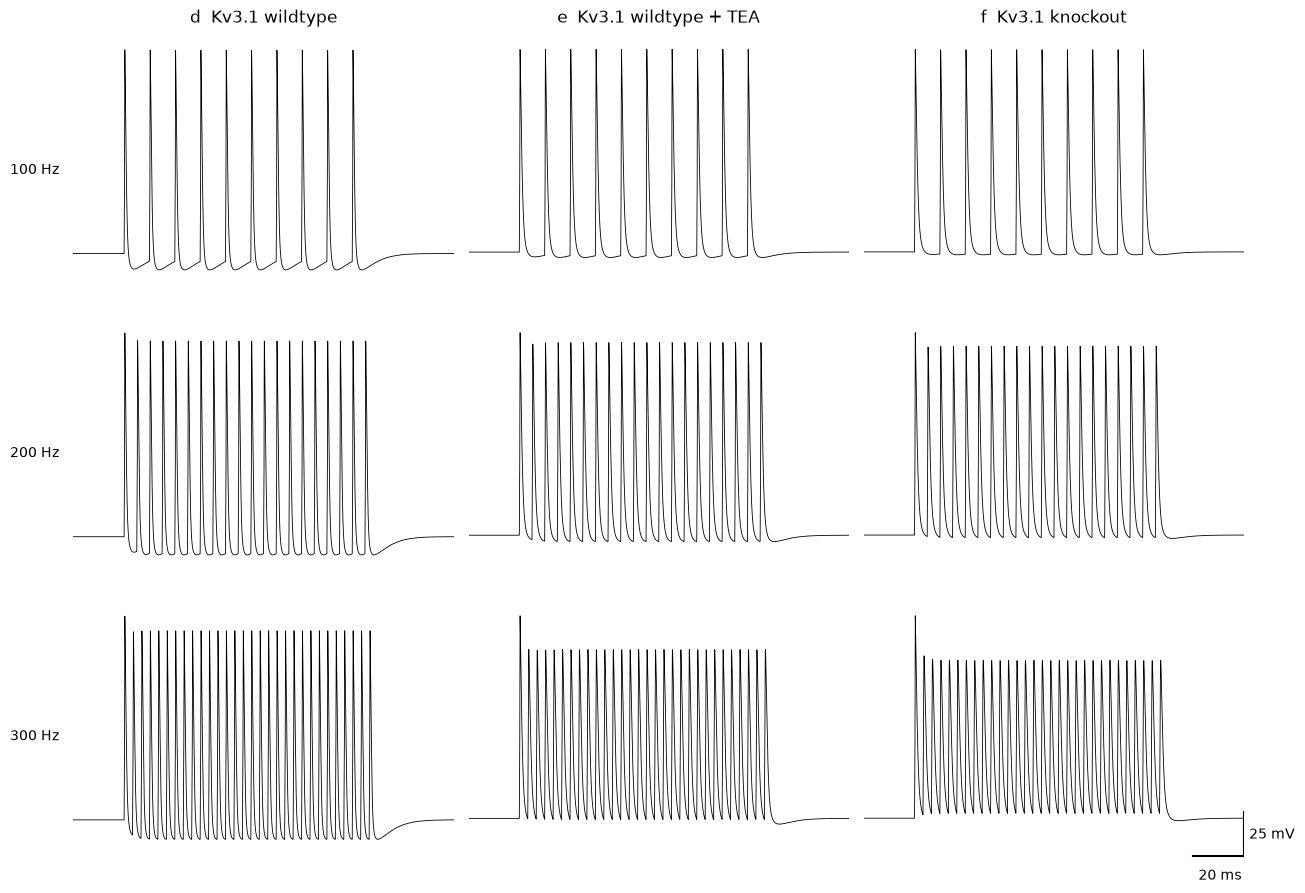

In [3]:
conditions_1 = ["Kv3.1 wildtype", "Kv3.1 wildtype + TEA", "Kv3.1 knockout"]
letters = ["d", "e", "f"]
freqs_1 = [100, 200, 300]

fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharey=True)
for j, cond in enumerate(conditions_1):
    for i, f in enumerate(freqs_1):
        n_pulses = int(100 * f / 1000)
        r = run_train(G_KV31[cond], f, n_pulses)
        ax = axes[i, j]
        ax.plot(r["t"] - T0, r["V"], "k", lw=0.6)
        ax.set_xlim(-20, 130)
        ax.set_ylim(-90, 60)
        ax.axis("off")
        if np.sum(~r["ok"]) > 0:
            fail = r["starts"][~r["ok"]] - T0
            ax.plot([fail[0], fail[-1]], [50, 50], "k")
            ax.text((fail[0] + fail[-1]) / 2, 53, "failure", ha="center")
        if i == 0:
            ax.set_title(letters[j] + "  " + cond)
        if j == 0:
            ax.text(-45, -20, str(f) + " Hz")
        print(cond, f, "Hz:", np.sum(r["ok"]), "/", n_pulses, "APs")

axes[2, 2].plot([110, 130], [-85, -85], "k")
axes[2, 2].plot([130, 130], [-85, -60], "k")
axes[2, 2].text(132, -75, "25 mV")
axes[2, 2].text(112, -98, "20 ms")
plt.tight_layout()
plt.show()

## Fig. 8

Control vs PMA, pulses 2 nA, 0.3 ms.

a: delay from the onset of the stimulus pulse to the peak of the AP (arrows = failures).
b: superimposed APs (failures omitted).

Data at 400 Hz: delay 0.99 +- 0.17 ms (control), 0.85 +- 0.11 ms (PMA).

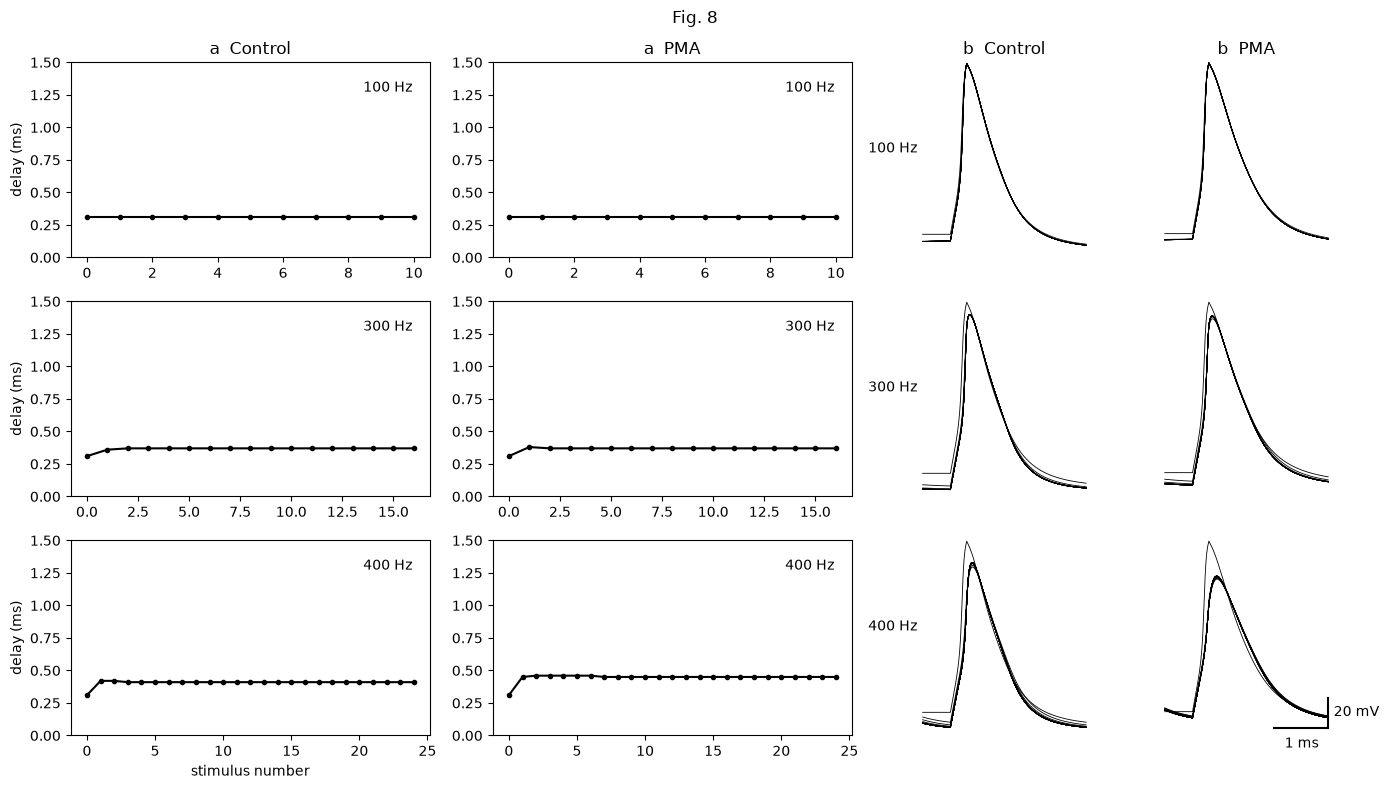

Control 100 Hz: 11 / 11 APs, delay = 0.31 +- 0.0 ms
Control 300 Hz: 17 / 17 APs, delay = 0.366 +- 0.014 ms
Control 400 Hz: 25 / 25 APs, delay = 0.407 +- 0.02 ms
PMA 100 Hz: 11 / 11 APs, delay = 0.31 +- 0.0 ms
PMA 300 Hz: 17 / 17 APs, delay = 0.367 +- 0.014 ms
PMA 400 Hz: 25 / 25 APs, delay = 0.446 +- 0.028 ms


In [4]:
conditions_8 = {"Control": G_KV31["Kv3.1 wildtype"], "PMA": G_KV31["PMA"]}
freqs_8 = [100, 300, 400]
n_stimuli = {100: 11, 300: 17, 400: 25}

res_8 = {}
for cond in conditions_8:
    for f in freqs_8:
        res_8[(cond, f)] = run_train(conditions_8[cond], f, n_stimuli[f])

fig, axes = plt.subplots(3, 4, figsize=(14, 8), gridspec_kw={"width_ratios": [2, 2, 1, 1]})
for j, cond in enumerate(conditions_8):
    for i, f in enumerate(freqs_8):
        r = res_8[(cond, f)]
        plot_delay(axes[i, j], r, str(f) + " Hz")
        plot_aps(axes[i, j + 2], r)
        if i == 0:
            axes[i, j].set_title("a  " + cond)
            axes[i, j + 2].set_title("b  " + cond)
for i, f in enumerate(freqs_8):
    axes[i, 0].set_ylabel("delay (ms)")
    axes[i, 2].text(-1.5, -10, str(f) + " Hz")
axes[2, 0].set_xlabel("stimulus number")
scale_bar(axes[2, 3])
fig.suptitle("Fig. 8")
plt.tight_layout()
plt.show()

for cond in conditions_8:
    for f in freqs_8:
        r = res_8[(cond, f)]
        d = r["delay"][r["ok"]]
        print(cond, f, "Hz:", np.sum(r["ok"]), "/", len(r["ok"]), "APs, delay =",
              round(d.mean(), 3), "+-", round(d.std(), 3), "ms")

## Fig. 9 (model, parameters as in the paper)

g_Kv3.1 = 150 nS (control) and 100 nS (reduction similar to PMA). Pulses: 1.4 nA, 0.25 ms. 100 ms trains.

a: delay from the onset of the stimulus pulse to the peak of the AP (arrows = failures).
b: superimposed APs (failures omitted).

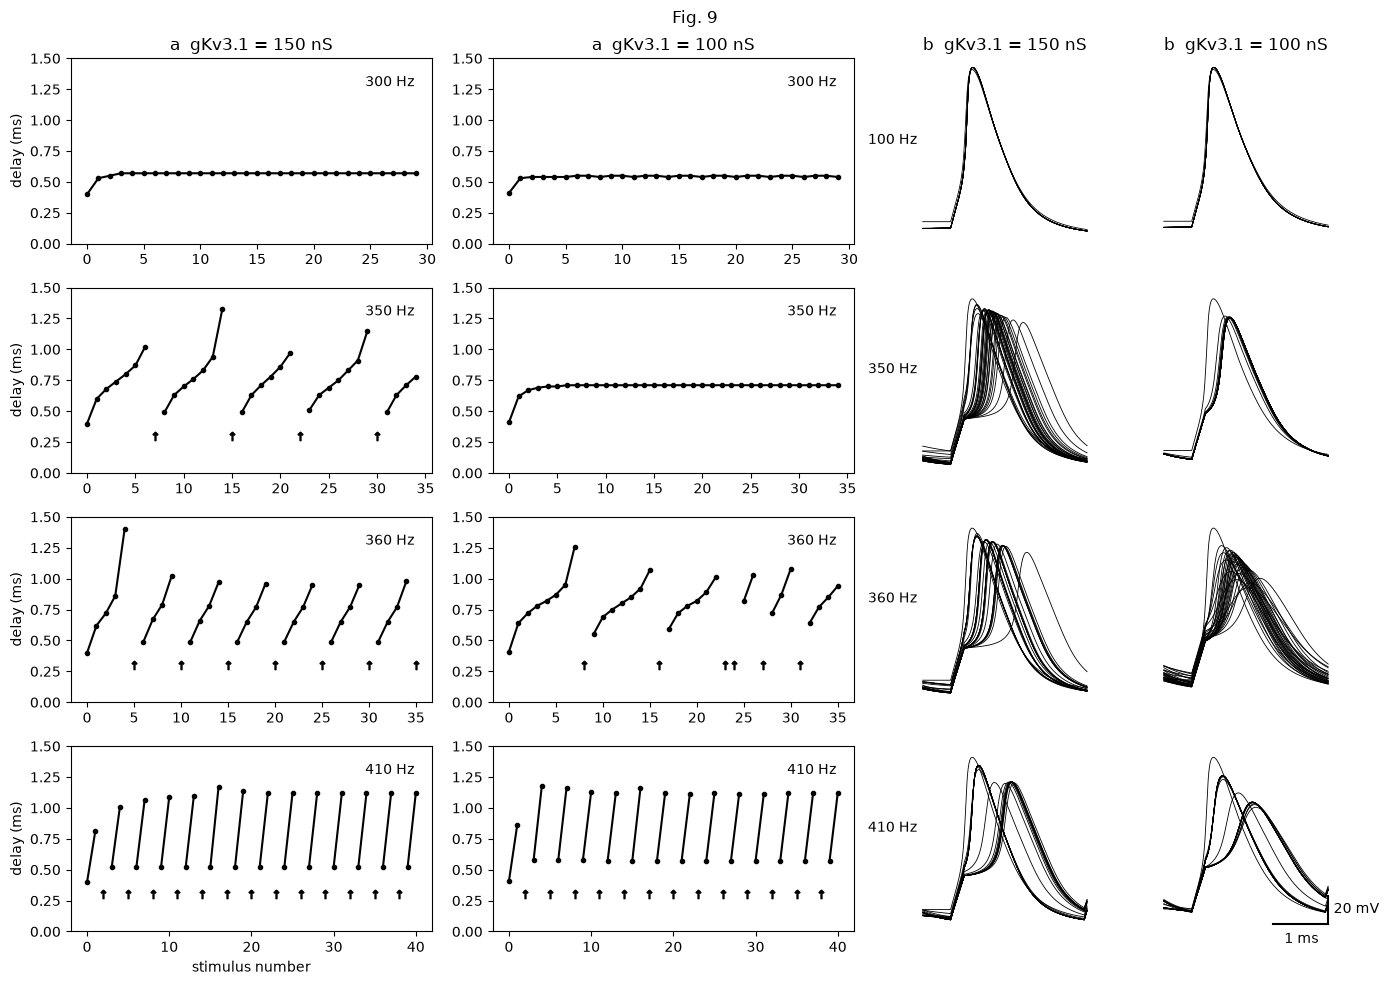

gKv3.1 = 150 nS 100 Hz: 10 / 10 APs, delay = 0.409 +- 0.003 ms
gKv3.1 = 150 nS 300 Hz: 30 / 30 APs, delay = 0.562 +- 0.031 ms
gKv3.1 = 150 nS 350 Hz: 31 / 35 APs, delay = 0.752 +- 0.197 ms
gKv3.1 = 150 nS 360 Hz: 29 / 36 APs, delay = 0.736 +- 0.214 ms
gKv3.1 = 150 nS 410 Hz: 28 / 41 APs, delay = 0.799 +- 0.295 ms
gKv3.1 = 100 nS 100 Hz: 10 / 10 APs, delay = 0.41 +- 0.0 ms
gKv3.1 = 100 nS 300 Hz: 30 / 30 APs, delay = 0.541 +- 0.025 ms
gKv3.1 = 100 nS 350 Hz: 35 / 35 APs, delay = 0.697 +- 0.052 ms
gKv3.1 = 100 nS 360 Hz: 30 / 36 APs, delay = 0.82 +- 0.171 ms
gKv3.1 = 100 nS 410 Hz: 28 / 41 APs, delay = 0.835 +- 0.281 ms


In [5]:
def plot_delay(ax, r, label):
    ok = r["ok"]
    number = np.arange(len(ok))
    y = r["delay"].copy()
    y[~ok] = np.nan
    ax.plot(number, y, "k.-")
    ax.plot(number[~ok], np.full(np.sum(~ok), 0.3), "k", marker=r"$\uparrow$", linestyle="none")
    ax.set_ylim(0, 1.5)
    ax.text(0.95, 0.85, label, transform=ax.transAxes, ha="right")


g_9 = {"gKv3.1 = 150 nS": 150.0, "gKv3.1 = 100 nS": 100.0}
freqs_9a = [300, 350, 360, 410]
freqs_9b = [100, 350, 360, 410]

res_9 = {}
for cond in g_9:
    for f in [100, 300, 350, 360, 410]:
        n_pulses = int(100 * f / 1000)
        res_9[(cond, f)] = run_train(g_9[cond], f, n_pulses, amp=1400.0, dur=0.25)

fig, axes = plt.subplots(4, 4, figsize=(14, 10), gridspec_kw={"width_ratios": [2, 2, 1, 1]})
for j, cond in enumerate(g_9):
    for i in range(4):
        plot_delay(axes[i, j], res_9[(cond, freqs_9a[i])], str(freqs_9a[i]) + " Hz")
        plot_aps(axes[i, j + 2], res_9[(cond, freqs_9b[i])])
        if i == 0:
            axes[i, j].set_title("a  " + cond)
            axes[i, j + 2].set_title("b  " + cond)
for i in range(4):
    axes[i, 0].set_ylabel("delay (ms)")
    axes[i, 2].text(-1.5, -10, str(freqs_9b[i]) + " Hz")
axes[3, 0].set_xlabel("stimulus number")
scale_bar(axes[3, 3])
fig.suptitle("Fig. 9")
plt.tight_layout()
plt.show()

for cond in g_9:
    for f in [100, 300, 350, 360, 410]:
        r = res_9[(cond, f)]
        d = r["delay"][r["ok"]]
        print(cond, f, "Hz:", np.sum(r["ok"]), "/", len(r["ok"]), "APs, delay =",
              round(d.mean(), 3), "+-", round(d.std(), 3), "ms")